# 03 · Signal research lab

**Who this is for:** quant researchers. It covers:
- the anatomy of the leader-minus-herd (LMH) signal;
- information coefficients by horizon and by year;
- incremental power over price factors (Fama–MacBeth);
- adding **your own signal** through the registry, auditing it for look-ahead and testing it inside the composite.

In [1]:
# fmflow-setup: runs as-is everywhere. In an installed environment it only locates the repository; on Google Colab,
# Binder or a Jupyter without the package, it downloads the repository once and installs it (about a minute).
import importlib, importlib.util, os, shutil, subprocess, sys
from pathlib import Path

REPO_URL = os.environ.get("FMFLOW_REPO_URL", "https://github.com/bahakh19/first-mover-flow")   # set it to use a fork


def _run(cmd: list, what: str, hint: str = "") -> None:
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode:
        raise RuntimeError(f"{what} failed:\n{(r.stderr or r.stdout).strip()[-1500:]}\n{hint}")


_here = Path.cwd()
_root = next((p for p in (_here, *_here.parents, _here / "first-mover-flow") if (p / "src" / "fmflow").is_dir()), None)
if _root is None:                                                  # notebooks need the repository's data/ folder
    _root = (_here / "first-mover-flow").resolve()
    print(f"Downloading {REPO_URL} ...")
    if shutil.which("git"):
        _run(["git", "clone", "-q", "--depth", "1", REPO_URL, str(_root)], f"git clone {REPO_URL}",
             "Is the repository public? For a fork or a local copy, set the environment variable FMFLOW_REPO_URL.")
    else:                                                          # no git: the GitHub zip archive of the main branch
        import io, urllib.request, zipfile
        with urllib.request.urlopen(REPO_URL.rstrip("/") + "/archive/refs/heads/main.zip") as _r:
            zipfile.ZipFile(io.BytesIO(_r.read())).extractall(_here)
        (_here / (REPO_URL.rstrip("/").split("/")[-1] + "-main")).rename(_root)
if importlib.util.find_spec("fmflow") is None:
    print("Installing fmflow and its dependencies (about a minute) ...")
    _target = f"{_root}[plot]"
    if importlib.util.find_spec("pip"):
        _run([sys.executable, "-m", "pip", "install", "-q", "-e", _target], "pip install")
    elif shutil.which("uv"):                                       # uv-created environments have no pip
        _run(["uv", "pip", "install", "-q", "--python", sys.executable, "-e", _target], "uv pip install")
    else:
        raise RuntimeError("this kernel has neither pip nor uv: install the package from a terminal (INSTALL.md)")
    sys.path.insert(0, str(_root / "src"))
    importlib.invalidate_caches()
os.chdir(_root / "notebooks")
print("fmflow", importlib.import_module("fmflow").__version__, "| repository:", _root)

fmflow 2.2.4 | repository: /home/claude/work/v22/repo


In [2]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from fmflow import StrategyConfig, load_prices, load_ratings, run_strategy
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
BLUE, ORANGE, GREEN, RED, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#9a9a9a"
P = load_prices(ROOT / "data/open/MarketData_Normalized.csv")
R = load_ratings(ROOT / "data/open/Ratings_Normalized.csv", P)
SIG = pd.read_csv(ROOT / "tests/fixtures/open_sig_gjr.csv.gz", index_col=0, parse_dates=True)   # cached GARCH forecasts
EV = slice("2024-01-05", "2026-08-05")                                                          # pre-registered window
CFG = StrategyConfig.fmf_n_scalable()                                                           # leg fraction 0.4
out = run_strategy(P, R, CFG, sig_vol=SIG)
print(f"{out.prices.shape[1]} stocks, {len(out.prices)} sessions, {len(out.ratings):,} accepted ratings")

30 stocks, 899 sessions, 2,363 accepted ratings


## 1. Anatomy of LMH

Every fresh revision is either a **leader**, a **herder** or neither:
- a **leader** revises on an information-event day, or after at least 10 silent sessions on the stock;
- a **herder** revises 3 to 15 sessions after the latest event cluster, in the cluster's direction.

LMH is the net direction of leaders minus herders over 126 sessions.

{'revision-flow': ['breadth_63', 'breadth_resid_mom', 'event_breadth_63', 'herders_only', 'leader_minus_herd', 'leaders_only'], 'price': ['high_52w', 'low_beta_252', 'low_vol_60', 'mom_12_1', 'mom_6_1', 'resid_mom_12_1', 'rev_1m'], 'analyst': ['cons_change_63', 'low_dispersion', 'tp_upside']}
coverage (share of stock-days with a value): LMH 0.53, leaders 0.74, herders 0.03


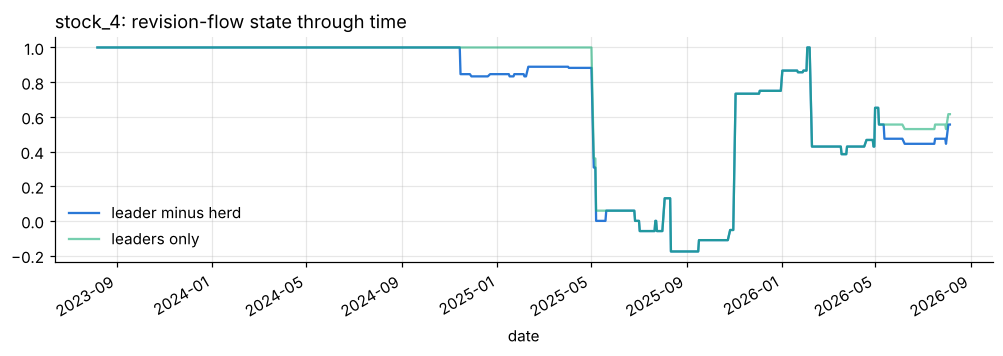

In [3]:
from fmflow.signals.registry import available_signals, signal_family
print({fam: [s for s in available_signals() if signal_family(s) == fam] for fam in ("revision-flow", "price", "analyst")})
lmh, lead, herd = (out.signals[k] for k in ("leader_minus_herd", "leaders_only", "herders_only"))
print("coverage (share of stock-days with a value): LMH %.2f, leaders %.2f, herders %.2f" %
      tuple(x.loc[EV].notna().mean().mean() for x in (lmh, lead, herd)))
s = lmh.loc[EV].notna().sum().idxmax()
fig, ax = plt.subplots(figsize=(11, 3))
lmh[s].plot(ax=ax, color=BLUE, label="leader minus herd"); lead[s].plot(ax=ax, color=GREEN, alpha=0.6, label="leaders only")
ax.legend(frameon=False); ax.set_title(f"{s}: revision-flow state through time", loc="left"); plt.show()

## 2. Predictive power by horizon and by year

`signal_ic_table` uses labels that **end inside** the evaluation window. Its *t*-statistic averages the standard errors of the *h* non-overlapping sub-samples, so it is not inflated by overlapping labels.

,1,5,10,21,42,63
breadth_63,0.009,0.008,0.015,0.051,0.123,0.191
event_breadth_63,0.000,-0.036,-0.059,-0.041,-0.011,0.050
breadth_resid_mom,-0.003,-0.010,0.009,0.020,0.067,0.121
leader_minus_herd,0.028,0.047,0.049,0.096,0.143,0.181
composite,0.023,0.032,0.040,0.073,0.121,0.163
leaders_only,0.035,0.058,0.066,0.087,0.143,0.174
herders_only,NaN,NaN,NaN,NaN,NaN,NaN


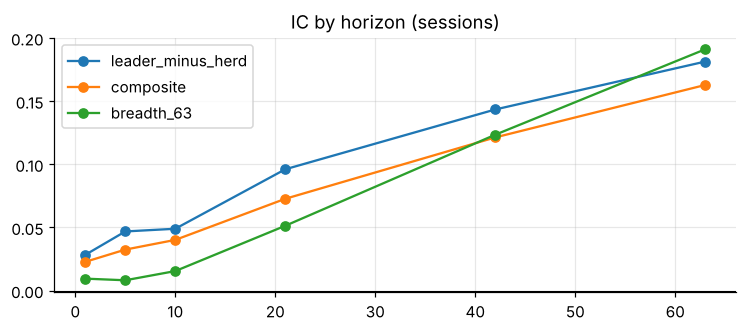

,2024,2025,2026
breadth_63,0.036,0.021,0.119
event_breadth_63,-0.230,-0.004,0.075
breadth_resid_mom,0.010,0.075,-0.047
leader_minus_herd,0.082,0.032,0.200
composite,0.024,0.071,0.150
leaders_only,0.079,0.030,0.187
herders_only,NaN,NaN,NaN


In [4]:
from fmflow.robustness import signal_ic_table
dec = pd.DataFrame({h: signal_ic_table(out, h, EV)["IC"] for h in (1, 5, 10, 21, 42, 63)})
display(dec.round(3))
dec.T[["leader_minus_herd", "composite", "breadth_63"]].plot(marker="o", figsize=(8, 3), title="IC by horizon (sessions)")
plt.axhline(0, color="k", lw=0.7); plt.show()
yearly = pd.DataFrame({y: signal_ic_table(out, 21, slice(f"{y}-01-01", f"{y}-12-31"))["IC"] for y in (2024, 2025, 2026)})
display(yearly.round(3))

## 3. Incremental to price factors? (Fama–MacBeth)

Regress 21-session forward returns on the cross-sectional rank of the signal and of four price controls every five sessions, with Newey–West *t*-statistics.

A revision signal that merely chases price loses its slope once momentum is controlled for. LMH is built to be different: herders follow price, leaders do not.

In [5]:
from fmflow.analytics.inference import fama_macbeth, forward_log_return
from fmflow.signals.price import price_signals
ps = price_signals(out.prices)
fwd = forward_log_return(out.prices, 21)
idx = out.prices.loc[EV].index[:-21]
ctr = {k: ps[k].loc[idx] for k in ("mom_12_1", "mom_6_1", "rev_1m", "low_vol_60")}
fm = {s: fama_macbeth(out.signals[s].loc[idx], ctr, fwd.loc[idx]).loc["feature", ["slope", "t_NW"]]
      for s in ("breadth_63", "event_breadth_63", "breadth_resid_mom", "leader_minus_herd")}
display(pd.DataFrame(fm).T)

,slope,t_NW
breadth_63,0.004,0.146
event_breadth_63,-0.102,-2.033
breadth_resid_mom,0.006,0.396
leader_minus_herd,0.075,4.291


## 4. Add your own signal

Any causal function of the `SignalContext` can be registered. The context gives you:
- `ctx.px` and `ctx.ret`;
- `ctx.snap`, the point-in-time analyst state;
- `ctx.cfg`;
- `ctx.extra`, your own data.

The example below builds **coverage momentum**: the change in the number of active analysts over 63 sessions. The idea is that brokers initiate coverage on names with improving prospects.

In [6]:
from fmflow.signals.registry import register_signal

@register_signal("coverage_momentum", overwrite=True, family="custom")
def coverage_momentum(ctx):
    n = ctx.snap.n_active.reindex(index=ctx.px.index, columns=ctx.px.columns)
    return np.log1p(n) - np.log1p(n.shift(63))

o2 = run_strategy(P, R, CFG.with_(signals=CFG.signals + ("coverage_momentum",)), sig_vol=SIG)
display(signal_ic_table(o2, 21, EV).loc[["coverage_momentum", "leader_minus_herd", "composite"]])

,IC,t_phase,p (one-sided),hit rate,coverage,days
coverage_momentum,-0.001,-0.025,0.510,0.553,1.000,626.000
leader_minus_herd,0.096,1.797,0.042,0.642,0.526,589.000
composite,0.033,0.838,0.204,0.581,1.000,626.000


In [7]:
# Mandatory before trusting it: the look-ahead audit, with a deliberately leaky control
from fmflow.robustness import truncation_check
register_signal("peek_5d", lambda ctx: ctx.px.shift(-5) / ctx.px - 1, overwrite=True)
tc = truncation_check(P, R, CFG.with_(allocator="EW", signals=("leader_minus_herd", "coverage_momentum", "peek_5d")), ["2025-03-31"])
display(tc[tc["object"].str.contains("coverage|peek")])

,T,object,max_abs_diff,nan_mismatches,causal
6,2025-03-31,signal:coverage_momentum,0.000,0,True
7,2025-03-31,signal:peek_5d,0.228,150,False


In [8]:
# Does it improve the book? Compare five-signal and four-signal composites on the same construction
from fmflow.analytics.metrics import perf_stats
cmp = {"FMF-N (4 signals)": out.net_returns, "FMF-N + coverage momentum": o2.net_returns}
display(pd.DataFrame({k: perf_stats(v.loc[EV])[["Sharpe", "Calmar", "Max drawdown"]] for k, v in cmp.items()}).T)
print("Caution: this comparison is made on the out-of-sample window. A real research process decides on a development "
      "window and confirms on a pre-registered one (see notebook 09).")

,Sharpe,Calmar,Max drawdown
FMF-N (4 signals),1.046,1.319,-0.080
FMF-N + coverage momentum,0.473,0.330,-0.095


Caution: this comparison is made on the out-of-sample window. A real research process decides on a development window and confirms on a pre-registered one (see notebook 09).
